# LOSO PCA of latent EEG representations

Each outer fold holds out one test subject and one rotating validation subject. PCA fitting, RGB scaling and stability estimation use training subjects only. Labelled visualizations use only the validation subject.

In [23]:
import random
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", message="Importing from timm.models.layers is deprecated")
warnings.filterwarnings("ignore", message="Importing from timm.models.registry is deprecated")
warnings.filterwarnings("ignore", message="enable_nested_tensor is True")

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import yaml
from sklearn.decomposition import PCA
from torch.utils.data import ConcatDataset, DataLoader, Subset

from eeg_preprocessing.loaders import CustomDataset, get_subject_ids
from utils.wrappers.base import SAMPLING_RATE

ROOT = Path.cwd()

LMDB_PATHS = {
    "BCI2A": "/projects/EEG-foundation-model/RECH202/data_preprocessed_normalized/BCI2A/bci2a.lmdb",
    "FACED": "/projects/EEG-foundation-model/RECH202/data_preprocessed_normalized/FACED/faced.lmdb",
    "PHYSIONETMI": "/projects/EEG-foundation-model/RECH202/data_preprocessed_normalized/PHYSIONETMI/physionetmi.lmdb",
}

DATASET = "BCI2A"
MODEL_NAME = "reve"
SEED = 100
N_COMPONENTS = 10
MAX_TRAIN_EPOCHS = 512
STABILITY_REPEATS = 5
STABILITY_FRACTION = 0.8
DISPLAY_FOLD = 0
BATCH_SIZE = 64
NUM_WORKERS = 0
PIN_MEMORY = torch.cuda.is_available()


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


class FeatureModel(nn.Module):
    def __init__(self, wrapper):
        super().__init__()
        self.wrapper = wrapper
        self.backbone = wrapper.backbone
        self.chan_conv = getattr(wrapper, "chan_conv", nn.Identity())

    def forward(self, x):
        return self.wrapper.forward_features(x)


def load_model_config(model_name):
    with open(ROOT / "utils" / "configs" / f"{model_name}.yaml") as file:
        return yaml.safe_load(file)


def load_wrapper_class(model_name):
    if model_name == "cbramod":
        from utils.wrappers.cbramod import CBraModWrapper
        return CBraModWrapper
    if model_name == "csbrain":
        from utils.wrappers.csbrain import CSBrainWrapper
        return CSBrainWrapper
    if model_name == "eegmamba":
        from utils.wrappers.eegmamba import EEGMambaWrapper
        return EEGMambaWrapper
    if model_name == "eegpt":
        from utils.wrappers.eegpt import EEGPTWrapper
        return EEGPTWrapper
    if model_name == "labram":
        from utils.wrappers.labram import LaBraMWrapper
        return LaBraMWrapper
    if model_name == "reve":
        from utils.wrappers.reve import ReveWrapper
        return ReveWrapper
    if model_name == "lumamba":
        from utils.wrappers.lumamba import LuMambaWrapper
        return LuMambaWrapper
    if model_name == "luna":
        from utils.wrappers.luna import LUNAWrapper
        return LUNAWrapper
    if model_name == "eegfm":
        from utils.wrappers.eegfm import EEGFMWrapper
        return EEGFMWrapper
    if model_name == "eegnet":
        from utils.wrappers.eegnet import EEGNetWrapper
        return EEGNetWrapper
    raise ValueError(f"Unknown model: {model_name}")


def load_model(model_name, dataset, device):
    config = load_model_config(model_name)
    channel_mode = config.get("channel_mode", "mapped")
    lmdb_path = LMDB_PATHS[dataset]
    first_subject = get_subject_ids(Path(lmdb_path))[0]
    sample, _ = CustomDataset(lmdb_path, [first_subject], channel_mode=channel_mode)[0]
    checkpoint = ROOT / config["pretrained_weights"] if config.get("use_pretrained_weights") else None
    if checkpoint is not None and not checkpoint.is_file():
        raise FileNotFoundError(f"Missing pretrained checkpoint: {checkpoint}")
    wrapper = load_wrapper_class(model_name)(
        ckpt_path=str(checkpoint) if checkpoint is not None else None,
        dropout=config.get("dropout", 0.0),
    )
    wrapper.build_backbone(n_channels=sample.shape[0], time_length=sample.shape[1])
    wrapper.freeze_backbone()
    return FeatureModel(wrapper).to(device), channel_mode


In [24]:
def make_dataset(subject_ids, channel_mode):
    return CustomDataset(
        LMDB_PATHS[DATASET],
        subject_ids=subject_ids,
        channel_mode=channel_mode,
        return_ch_names=False,
        scale_factor=1.0,
    )


def make_loader(dataset):
    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY,
        persistent_workers=False,
    )


def make_balanced_train_loader(subject_ids, channel_mode, seed):
    rng = np.random.default_rng(seed)
    epochs_per_subject = max(1, MAX_TRAIN_EPOCHS // len(subject_ids))
    subsets = []
    for subject_id in subject_ids:
        dataset = make_dataset([subject_id], channel_mode)
        size = min(epochs_per_subject, len(dataset))
        indices = np.sort(rng.choice(len(dataset), size=size, replace=False)).tolist()
        subsets.append(Subset(dataset, indices))
    return make_loader(ConcatDataset(subsets))


@torch.inference_mode()
def extract_features(model, loader, return_signals=False, return_labels=False):
    device = next(model.parameters()).device
    model.eval()
    total = len(loader.dataset)
    features = None
    signals = None
    labels = None
    offset = 0
    for x, y in loader:
        z = model(model.wrapper.preprocess(x.to(device, non_blocking=True).float()))
        batch_features = z.flatten(1).float().cpu().numpy()
        batch_size = len(x)
        if features is None:
            features = np.empty((total, batch_features.shape[1]), dtype=np.float32)
            if return_signals:
                signals = np.empty((total, *x.shape[1:]), dtype=np.float32)
            if return_labels:
                labels = np.empty(total, dtype=np.int64)
        features[offset:offset + batch_size] = batch_features
        if return_signals:
            signals[offset:offset + batch_size] = x.numpy()
        if return_labels:
            labels[offset:offset + batch_size] = y.numpy()
        offset += batch_size
    return features[:offset], signals, labels


In [25]:
def fit_pca(train_features, seed):
    pca = PCA(n_components=N_COMPONENTS, svd_solver="randomized", random_state=seed)
    train_projected = pca.fit_transform(train_features)
    return pca, train_projected


def rgb_from_training_projection(train_projected, projected):
    low, high = np.quantile(train_projected[:, :3], [0.01, 0.99], axis=0)
    return np.clip((projected[:, :3] - low) / (high - low + 1e-8), 0, 1)


def pca_stability(train_features, reference_pca, seed):
    rng = np.random.default_rng(seed)
    subset_size = max(N_COMPONENTS + 1, round(len(train_features) * STABILITY_FRACTION))
    scores = []
    for repeat in range(STABILITY_REPEATS):
        indices = rng.choice(len(train_features), size=subset_size, replace=False)
        sampled_pca = PCA(
            n_components=N_COMPONENTS,
            svd_solver="randomized",
            random_state=seed + repeat + 1,
        ).fit(train_features[indices])
        singular_values = np.linalg.svd(
            reference_pca.components_ @ sampled_pca.components_.T,
            compute_uv=False,
        )
        scores.append(float(np.mean(np.clip(singular_values, 0, 1) ** 2)))
    return float(np.mean(scores)), float(np.std(scores))


def captured_test_variance(pca, test_features):
    centered = test_features - pca.mean_
    projected = pca.transform(test_features)
    denominator = np.square(centered).sum()
    return float(np.square(projected).sum() / max(denominator, 1e-12))


In [26]:
def plot_label_colors(pca_rgb, labels, subject_id):
    classes = np.unique(labels)
    mean_rgb = np.stack([pca_rgb[labels == class_id].mean(axis=0) for class_id in classes])
    std_rgb = np.stack([pca_rgb[labels == class_id].std(axis=0) for class_id in classes])
    fig, ax = plt.subplots(figsize=(1.8 * len(classes), 2.6), dpi=160)
    ax.imshow(mean_rgb[None], aspect="auto", interpolation="nearest")
    ax.set_xticks(np.arange(len(classes)))
    ax.set_xticklabels([f"Class {class_id}\n(n={(labels == class_id).sum()})" for class_id in classes])
    ax.set_yticks([])
    ax.set_title(f"Validation subject {subject_id}: mean PCA RGB by class")
    fig.tight_layout()
    plt.show()
    for class_id, mean, std in zip(classes, mean_rgb, std_rgb):
        print(f"Class {class_id}: mean={np.round(mean, 3)}, std={np.round(std, 3)}")


def plot_pca_scatter(projected, labels, explained_variance_ratio, subject_id):
    fig, ax = plt.subplots(figsize=(7, 5), dpi=160)
    for class_id in np.unique(labels):
        points = projected[labels == class_id]
        ax.scatter(points[:, 0], points[:, 1], s=14, alpha=0.55, label=f"Class {class_id}")
    ax.set_xlabel(f"PC1 ({explained_variance_ratio[0]:.1%} training variance)")
    ax.set_ylabel(f"PC2 ({explained_variance_ratio[1]:.1%} training variance)")
    ax.set_title(f"Validation subject {subject_id} projected onto training PCA")
    ax.legend(frameon=False)
    fig.tight_layout()
    plt.show()


def plot_pca_with_signal(pca_rgb, signals, labels, subject_id, channel=2, n_segments=8, seed=SEED):
    if channel < 0 or channel >= signals.shape[1]:
        raise ValueError(f"Invalid channel {channel} for {signals.shape[1]} channels")
    rng = np.random.default_rng(seed)
    indices = np.sort(rng.choice(len(signals), size=min(n_segments, len(signals)), replace=False))
    epoch_length = signals.shape[-1]
    epoch_seconds = epoch_length / SAMPLING_RATE
    signal = signals[indices, channel].reshape(-1)
    time = np.arange(len(signal)) / SAMPLING_RATE
    fig, ax = plt.subplots(figsize=(16, 4), dpi=160)
    for position, index in enumerate(indices):
        left = position * epoch_seconds
        right = (position + 1) * epoch_seconds
        ax.axvspan(left, right, color=pca_rgb[index], alpha=0.4, linewidth=0)
        if position:
            ax.axvline(left, color="0.45", linewidth=0.8, linestyle="--")
        ax.text(
            (left + right) / 2,
            1.01,
            f"Class {labels[index]}",
            transform=ax.get_xaxis_transform(),
            ha="center",
            va="bottom",
        )
    ax.plot(time, signal, color="black", linewidth=0.6)
    ax.set_xlim(0, len(indices) * epoch_seconds)
    ax.set_xlabel("Time across separate validation epochs (s)")
    ax.set_ylabel(f"Normalized EEG, channel {channel}")
    ax.set_title(f"Validation subject {subject_id}: independent epochs and PCA colors", y=1.15)
    fig.tight_layout(rect=(0, 0, 1, 0.9))
    plt.show()


def plot_loso_summary(variances, stability_means, stability_stds):
    components = np.arange(1, N_COMPONENTS + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4), dpi=160)
    axes[0].bar(components, variances.mean(axis=0), yerr=variances.std(axis=0), capsize=3)
    axes[0].set_xticks(components)
    axes[0].set_xlabel("Principal component")
    axes[0].set_ylabel("Training explained variance ratio")
    axes[0].set_title("LOSO training variance: mean ± fold standard deviation")
    folds = np.arange(1, len(stability_means) + 1)
    axes[1].errorbar(folds, stability_means, yerr=stability_stds, marker="o", capsize=3)
    axes[1].set_xticks(folds)
    axes[1].set_ylim(0, 1.02)
    axes[1].set_xlabel("LOSO fold")
    axes[1].set_ylabel("Top-10 subspace stability")
    axes[1].set_title("Training-only PCA stability")
    fig.tight_layout()
    plt.show()


In [27]:
seed_everything(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
lmdb_path = Path(LMDB_PATHS[DATASET])
subjects = list(get_subject_ids(lmdb_path))
if len(subjects) < 3:
    raise ValueError("LOSO with an internal validation subject requires at least three subjects")
model, channel_mode = load_model(MODEL_NAME, DATASET, device)
print(f"Dataset: {DATASET}; subjects: {len(subjects)}; device: {device}")
print(f"Model: {MODEL_NAME}; channel mode: {channel_mode}")


[REVE] loaded pretrained weights from /home/infres/yrothlin-24/EEG_Benchmark/models/checkpoints/reve-base
Dataset: BCI2A; subjects: 9; device: cuda
Model: reve; channel mode: mapped


In [28]:
fold_results = []
validation_view = None

for fold, test_subject in enumerate(subjects):
    validation_subject = subjects[(fold + 1) % len(subjects)]
    train_subjects = [
        subject for subject in subjects
        if subject not in {test_subject, validation_subject}
    ]
    fold_seed = SEED + fold * 100
    train_loader = make_balanced_train_loader(train_subjects, channel_mode, fold_seed)
    train_features, _, _ = extract_features(model, train_loader)
    pca, train_projected = fit_pca(train_features, fold_seed)
    stability_mean, stability_std = pca_stability(train_features, pca, fold_seed)

    test_loader = make_loader(make_dataset([test_subject], channel_mode))
    test_features, _, _ = extract_features(model, test_loader)
    test_capture = captured_test_variance(pca, test_features)

    fold_results.append({
        "fold": fold + 1,
        "test_subject": test_subject,
        "validation_subject": validation_subject,
        "variance": pca.explained_variance_ratio_.copy(),
        "stability_mean": stability_mean,
        "stability_std": stability_std,
        "test_capture": test_capture,
    })

    if fold == DISPLAY_FOLD:
        validation_loader = make_loader(make_dataset([validation_subject], channel_mode))
        validation_features, signals, labels = extract_features(
            model,
            validation_loader,
            return_signals=True,
            return_labels=True,
        )
        validation_projected = pca.transform(validation_features)
        validation_view = {
            "subject": validation_subject,
            "projected": validation_projected,
            "rgb": rgb_from_training_projection(train_projected, validation_projected),
            "signals": signals,
            "labels": labels,
            "variance": pca.explained_variance_ratio_.copy(),
        }

    print(
        f"Fold {fold + 1}/{len(subjects)} | test={test_subject} | val={validation_subject} | "
        f"stability={stability_mean:.3f} ± {stability_std:.3f} | "
        f"test top-10 capture={test_capture:.3%}"
    )
    del train_features, train_projected, test_features
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


Fold 1/9 | test=A01 | val=A02 | stability=0.931 ± 0.018 | test top-10 capture=11.050%
Fold 2/9 | test=A02 | val=A03 | stability=0.905 ± 0.033 | test top-10 capture=15.971%
Fold 3/9 | test=A03 | val=A04 | stability=0.902 ± 0.029 | test top-10 capture=12.794%
Fold 4/9 | test=A04 | val=A05 | stability=0.933 ± 0.033 | test top-10 capture=12.832%
Fold 5/9 | test=A05 | val=A06 | stability=0.903 ± 0.025 | test top-10 capture=17.465%
Fold 6/9 | test=A06 | val=A07 | stability=0.919 ± 0.018 | test top-10 capture=12.476%
Fold 7/9 | test=A07 | val=A08 | stability=0.895 ± 0.024 | test top-10 capture=14.088%
Fold 8/9 | test=A08 | val=A09 | stability=0.891 ± 0.029 | test top-10 capture=11.931%
Fold 9/9 | test=A09 | val=A01 | stability=0.906 ± 0.023 | test top-10 capture=18.092%


Explained training variance across LOSO folds
PC01: 5.192% ± 0.394%
PC02: 2.968% ± 0.275%
PC03: 2.030% ± 0.072%
PC04: 1.841% ± 0.036%
PC05: 1.748% ± 0.040%
PC06: 1.638% ± 0.028%
PC07: 1.561% ± 0.025%
PC08: 1.483% ± 0.037%
PC09: 1.405% ± 0.015%
PC10: 1.337% ± 0.037%
Cumulative top-10 variance: 21.202% ± 0.306%
Top-10 stability: 0.909 ± 0.014 across folds
Held-out top-10 variance capture: 14.078% ± 2.374%


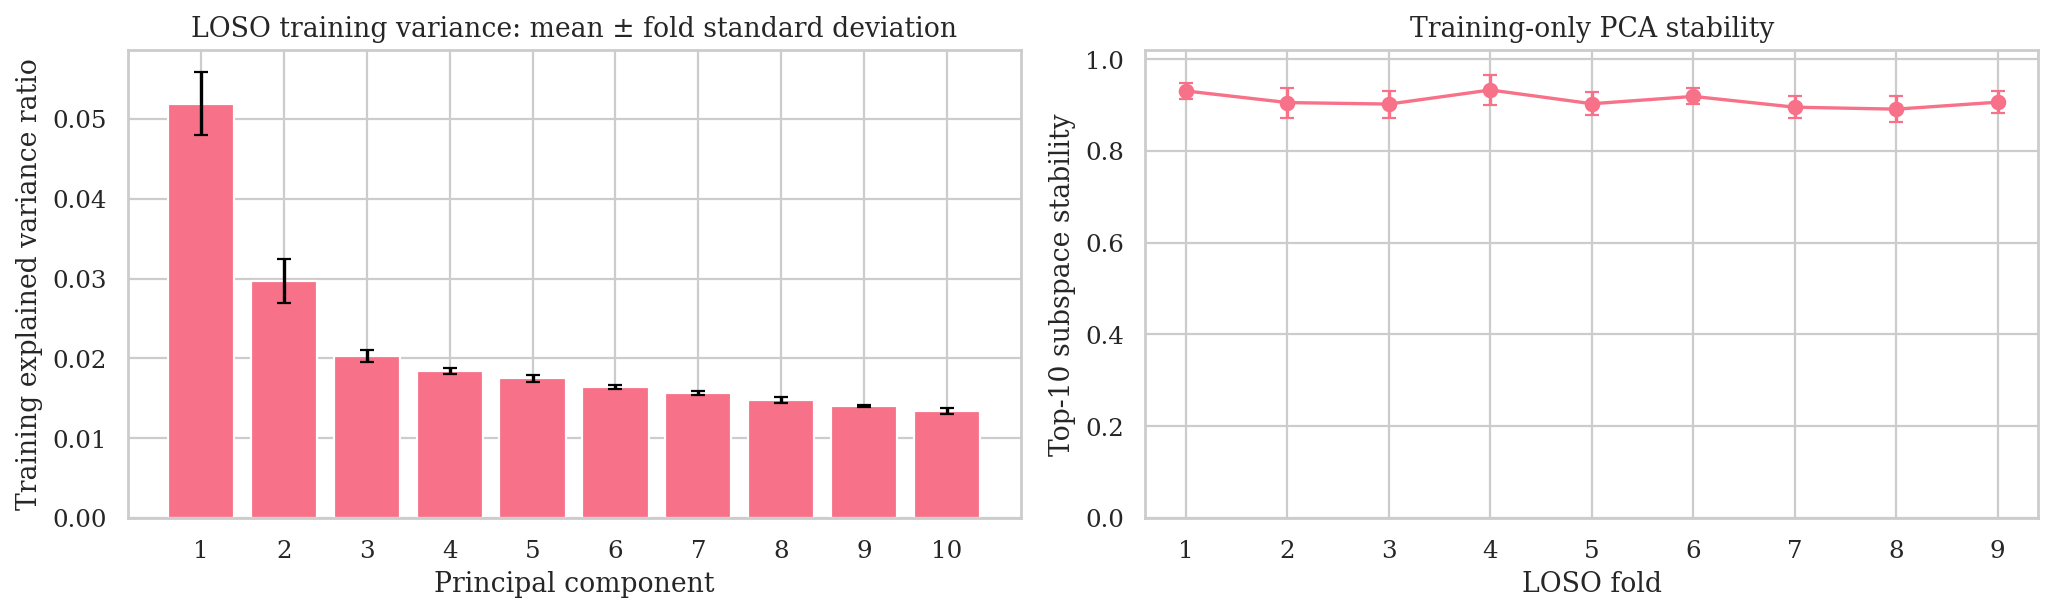

In [29]:
fold_variances = np.stack([result["variance"] for result in fold_results])
stability_means = np.array([result["stability_mean"] for result in fold_results])
stability_stds = np.array([result["stability_std"] for result in fold_results])
test_captures = np.array([result["test_capture"] for result in fold_results])

print("Explained training variance across LOSO folds")
for component, mean, std in zip(
    range(1, N_COMPONENTS + 1),
    fold_variances.mean(axis=0),
    fold_variances.std(axis=0),
):
    print(f"PC{component:02d}: {mean:.3%} ± {std:.3%}")
print(f"Cumulative top-10 variance: {fold_variances.sum(axis=1).mean():.3%} ± {fold_variances.sum(axis=1).std():.3%}")
print(f"Top-10 stability: {stability_means.mean():.3f} ± {stability_means.std():.3f} across folds")
print(f"Held-out top-10 variance capture: {test_captures.mean():.3%} ± {test_captures.std():.3%}")

plot_loso_summary(fold_variances, stability_means, stability_stds)


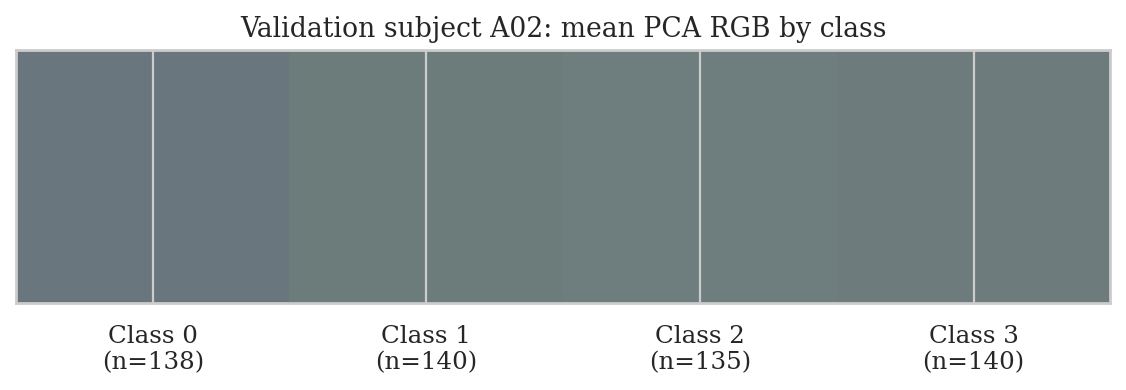

Class 0: mean=[0.415 0.465 0.491], std=[0.157 0.224 0.162]
Class 1: mean=[0.427 0.49  0.483], std=[0.148 0.195 0.146]
Class 2: mean=[0.434 0.492 0.493], std=[0.149 0.204 0.173]
Class 3: mean=[0.432 0.486 0.489], std=[0.147 0.202 0.148]


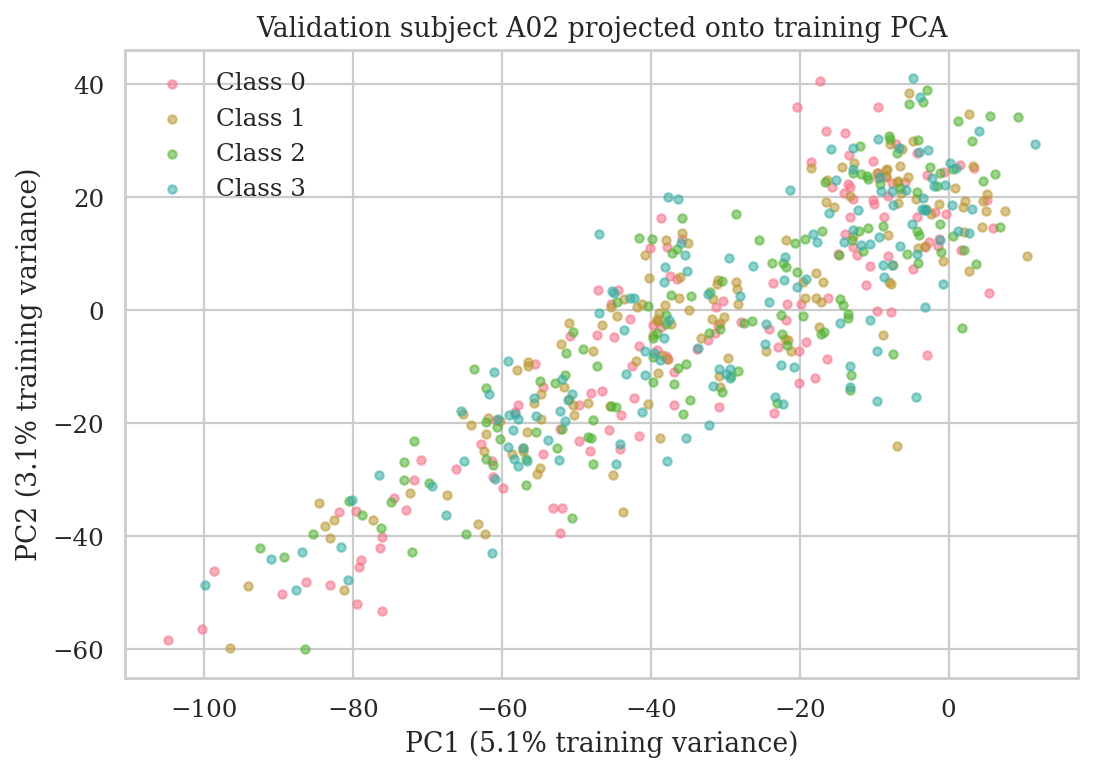

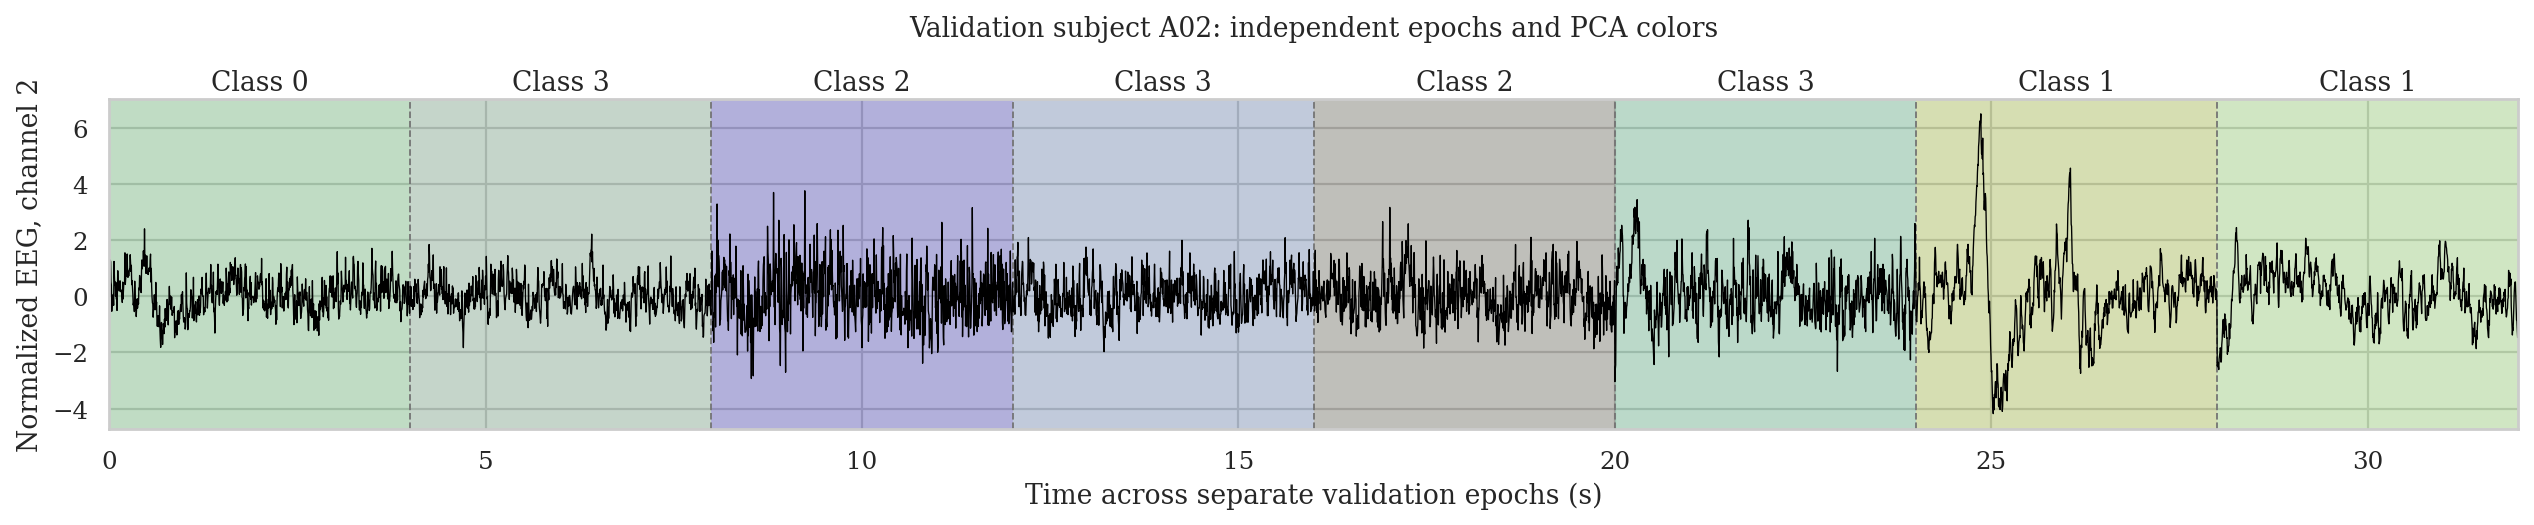

In [30]:
plot_label_colors(
    validation_view["rgb"],
    validation_view["labels"],
    validation_view["subject"],
)
plot_pca_scatter(
    validation_view["projected"],
    validation_view["labels"],
    validation_view["variance"],
    validation_view["subject"],
)
plot_pca_with_signal(
    validation_view["rgb"],
    validation_view["signals"],
    validation_view["labels"],
    validation_view["subject"],
    channel=2,
)


## Interpretation

The ten explained-variance ratios and the stability score are computed without test data. Stability is the mean squared cosine of the principal angles between the reference top-10 training subspace and top-10 subspaces fitted on five reproducible 80% training subsets; 1 indicates identical subspaces.

The held-out variance capture is the fraction of test energy, centered with the training mean, represented by the ten training components. Test labels are never used. Labelled colors, scatter points and EEG epochs come only from the rotating validation subject of the selected display fold. Separate EEG epochs are not presented as a continuous recording.